In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import yfinance as yf
import torch
import torch.nn as nn

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# You can write up to 5GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
data = yf.download("AMZN", start="2006-01-01", end="2018-01-01")
data.columns = data.columns.droplevel(1)
data.reset_index(inplace=True)
data.head()

[*********************100%***********************]  1 of 1 completed


Price,Date,Adj Close,Close,High,Low,Open,Volume
0,2006-01-03,2.3790,2.3790,2.3925,2.3125,2.3735,151644000
1,2006-01-04,2.3625,2.3625,2.3865,2.3345,2.3745,148818000
2,2006-01-05,2.3825,2.3825,2.4100,2.3555,2.3580,108344000
3,2006-01-06,2.3935,2.3935,2.4290,2.3660,2.3985,123058000
4,2006-01-09,2.3540,2.3540,2.3550,2.3200,2.3275,178862000


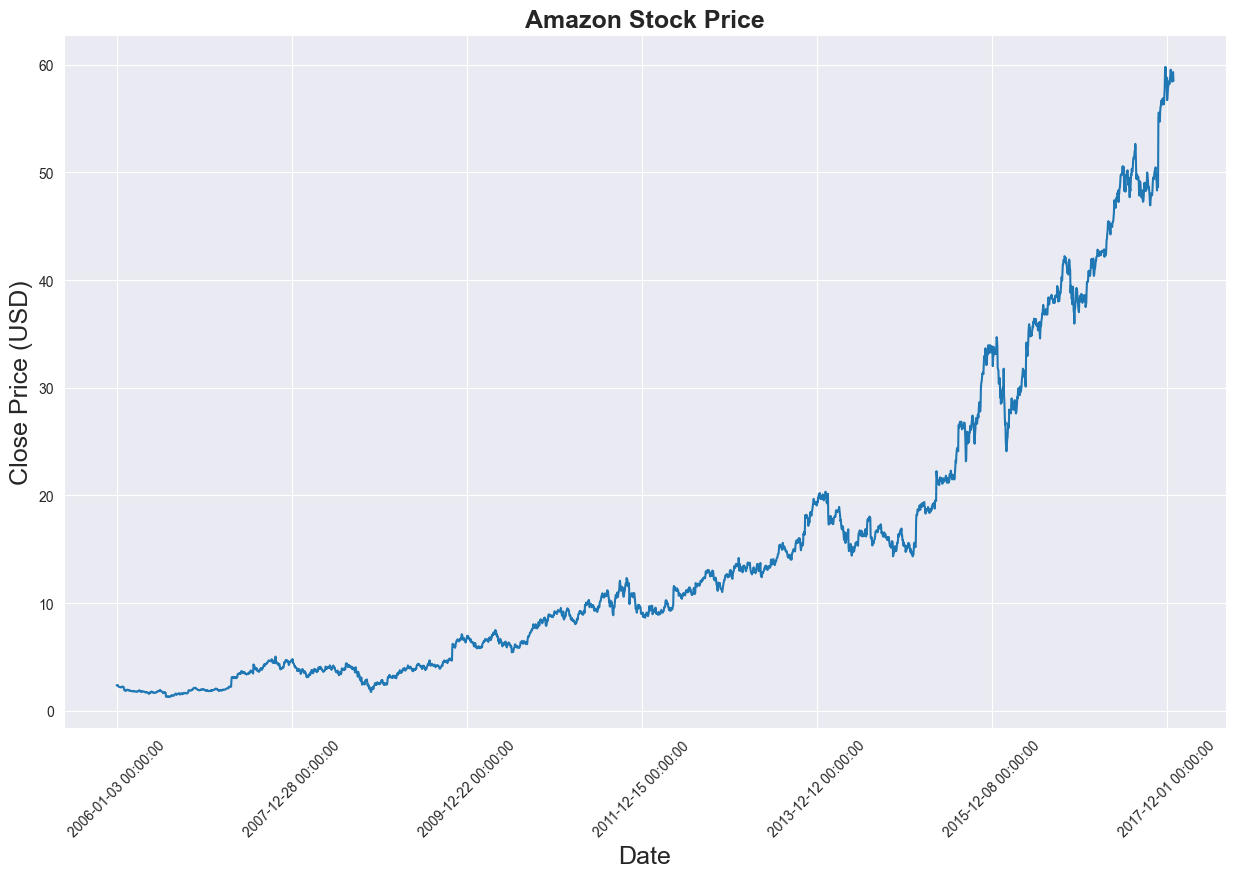

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("darkgrid")
plt.figure(figsize = (15,9))
plt.plot(data[['Close']])
plt.xticks(range(0,data.shape[0],500),data['Date'].loc[::500],rotation=45)
plt.title("Amazon Stock Price",fontsize=18, fontweight='bold')
plt.xlabel('Date',fontsize=18)
plt.ylabel('Close Price (USD)',fontsize=18)
plt.show()

## Normalize data

In [4]:
price = data[['Close']]
price.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3020 entries, 0 to 3019
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   3020 non-null   float64
dtypes: float64(1)
memory usage: 23.7 KB


In [5]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(-1, 1))
price['Close'] = scaler.fit_transform(price['Close'].values.reshape(-1,1))

C:\Users\luis\AppData\Local\Temp\ipykernel_31972\68737012.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  price['Close'] = scaler.fit_transform(price['Close'].values.reshape(-1,1))


In [6]:
split = int(len(price) * 0.80)
price_train = price[:split]
train_x = price_train[:-1].to_numpy()
train_y = price_train[1:].to_numpy()
price_test = price[split:]
test_x = price_test[:-1].to_numpy()
test_y = price_test[1:].to_numpy()

In [7]:
from torch.utils.data import Dataset, DataLoader

class TimeSeriesDataset(Dataset):
    def __init__(self, x, y, block_size):
        self.block_size = block_size
        self.x = torch.tensor(x, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.y) - self.block_size + 1

    def __getitem__(self, idx):
        if idx + self.block_size > len(self.x):
            raise IndexError("Index out of bounds")
        return (
            self.x[idx:idx+self.block_size],
            self.y[idx+self.block_size-1].unsqueeze(-1)
        )

In [8]:

train_data = TimeSeriesDataset(train_x, train_y, block_size=10)
test_data = TimeSeriesDataset(test_x, test_y, block_size=10)

batch_size = 16
train_loader = DataLoader(dataset=train_data, batch_size=batch_size, shuffle=True, num_workers=0)
test_loader = DataLoader(dataset=test_data, batch_size=batch_size, shuffle=False, num_workers=0)

In [9]:
input_dim = 1
hidden_dim = 32
num_layers = 2
output_dim = 1
num_epochs = 100

In [10]:
class LSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
        super(LSTM, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        # h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).requires_grad_()
        # c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).requires_grad_()
        # out, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach()))
        out, _ = self.lstm(x)
        out = self.fc(out[:, -1, :]) 
        return out

In [11]:
model = LSTM(input_dim=input_dim, hidden_dim=hidden_dim, output_dim=output_dim, num_layers=num_layers)
criterion = torch.nn.MSELoss(reduction='mean')
optimiser = torch.optim.Adam(model.parameters(), lr=0.01)

In [12]:
train_losses = np.zeros(num_epochs)
test_losses = np.zeros(num_epochs)

for epoch in range(num_epochs):
    epoch_loss = 0
    total_samples = 0


    model.train()
    for idx, (x, y) in enumerate(train_loader):
        optimiser.zero_grad()

        outputs = model(x) # (batch_size, 1)
        loss = criterion(outputs, y) # (batch_size, 1)

        loss.backward()
        optimiser.step()

        epoch_loss += loss.item()
        total_samples += x.size(0)
    
    print(f'Epoch {epoch} Train Loss: {epoch_loss / total_samples}')
    train_losses[epoch] = epoch_loss / total_samples

    # model.eval()
    # epoch_loss = 0
    # total_samples = 0
    # with torch.no_grad():
    #     for idx, (x, y) in enumerate(test_loader):
    #         outputs = model(x)
    #         loss = criterion(outputs, y)

    #         epoch_loss += loss.item()
    #         total_samples += x.size(0)
    # test_losses[epoch] = epoch_loss / total_samples


c:\Users\luis\Documents\GitHub\QTG\.venv\Lib\site-packages\torch\nn\modules\loss.py:608: UserWarning: Using a target size (torch.Size([16, 1, 1])) that is different to the input size (torch.Size([16, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)
c:\Users\luis\Documents\GitHub\QTG\.venv\Lib\site-packages\torch\nn\modules\loss.py:608: UserWarning: Using a target size (torch.Size([6, 1, 1])) that is different to the input size (torch.Size([6, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


Epoch 0 Train Loss: 0.0033992183737685954
Epoch 1 Train Loss: 0.002569774785470016
Epoch 2 Train Loss: 0.0026744325805520474
Epoch 3 Train Loss: 0.0025983915113823074
Epoch 4 Train Loss: 0.002611417700370103
Epoch 5 Train Loss: 0.002564288693977983
Epoch 6 Train Loss: 0.0025815079979604715
Epoch 7 Train Loss: 0.002612065012912798
Epoch 8 Train Loss: 0.0026129842275197765
Epoch 9 Train Loss: 0.002595361861371662
Epoch 10 Train Loss: 0.0025444010029533758
Epoch 11 Train Loss: 0.0025525084756320947
Epoch 12 Train Loss: 0.0025523286715385227
Epoch 13 Train Loss: 0.002541581882552514
Epoch 14 Train Loss: 0.0025928803229532636
Epoch 15 Train Loss: 0.002587194651665657
Epoch 16 Train Loss: 0.0026022446804764314
Epoch 17 Train Loss: 0.0025548390271521466
Epoch 18 Train Loss: 0.0025553169899487733
Epoch 19 Train Loss: 0.0025714128661408387
Epoch 20 Train Loss: 0.002563105245041084
Epoch 21 Train Loss: 0.002555140028595429
Epoch 22 Train Loss: 0.0025606653749856074
Epoch 23 Train Loss: 0.0025556

In [13]:
train_data.x.shape

torch.Size([2415, 1])

In [14]:
outs = np.empty(0)
model.eval()

outputs = model(train_data.x)
outs = np.append(outs, outputs.detach().numpy())

outs.shape

IndexError: too many indices for tensor of dimension 2

In [17]:
# import time

# hist = np.zeros(num_epochs)
# start_time = time.time()
# lstm = []

# for t in range(num_epochs):
#     y_train_pred = model(x_train)

#     loss = criterion(y_train_pred, y_train)
#     print("Epoch ", t, "MSE: ", loss.item())
#     hist[t] = loss.item()

#     optimiser.zero_grad()
#     loss.backward()
#     optimiser.step()
    
# training_time = time.time()-start_time
# print("Training time: {}".format(training_time))

In [18]:
# predict = pd.DataFrame(scaler.inverse_transform(y_train_pred.detach().numpy()))
# original = pd.DataFrame(scaler.inverse_transform(y_train.detach().numpy()))

In [19]:
predict = pd.DataFrame(scaler.inverse_transform(outs.reshape(-1,1)))
original = pd.DataFrame(scaler.inverse_transform(y_train.detach().numpy()))

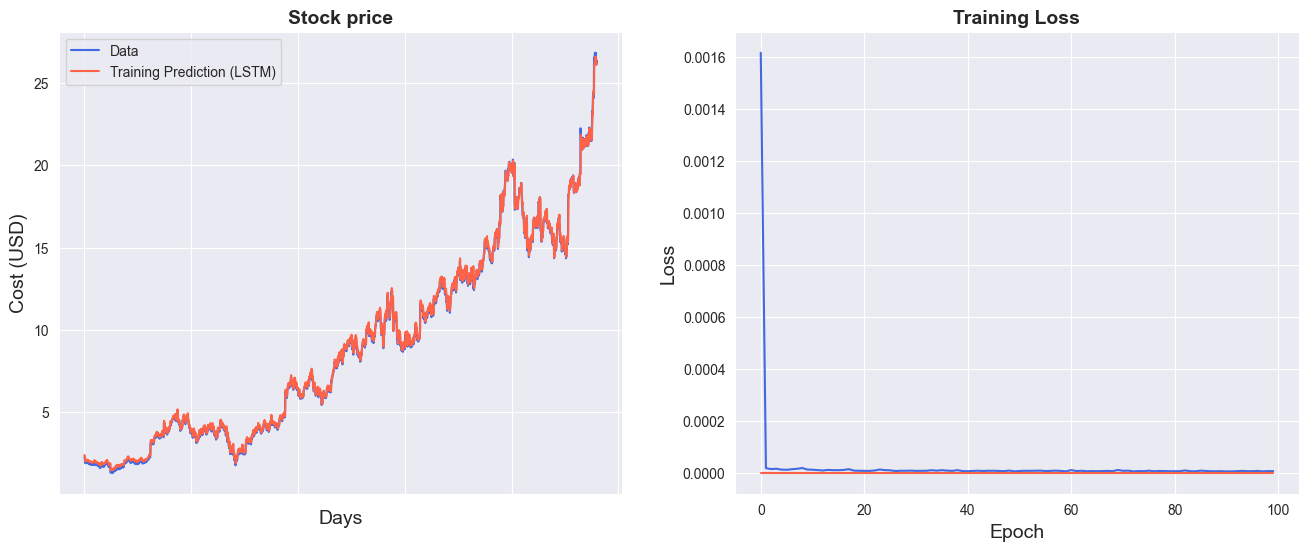

In [20]:
import seaborn as sns
sns.set_style("darkgrid")    

fig = plt.figure()
fig.subplots_adjust(hspace=0.2, wspace=0.2)

plt.subplot(1, 2, 1)
ax = sns.lineplot(x = original.index, y = original[0], label="Data", color='royalblue')
ax = sns.lineplot(x = predict.index, y = predict[0], label="Training Prediction (LSTM)", color='tomato')
ax.set_title('Stock price', size = 14, fontweight='bold')
ax.set_xlabel("Days", size = 14)
ax.set_ylabel("Cost (USD)", size = 14)
ax.set_xticklabels('', size=10)


plt.subplot(1, 2, 2)
ax = sns.lineplot(data=train_losses, color='royalblue')
ax = sns.lineplot(data=test_losses, color='tomato')
ax.set_xlabel("Epoch", size = 14)
ax.set_ylabel("Loss", size = 14)
ax.set_title("Training Loss", size = 14, fontweight='bold')
fig.set_figheight(6)
fig.set_figwidth(16)

In [21]:
import math, time
from sklearn.metrics import mean_squared_error

# make predictions
y_test_pred = model(x_test)

# invert predictions
y_train_pred = scaler.inverse_transform(y_train_pred.detach().numpy())
y_train = scaler.inverse_transform(y_train.detach().numpy())
y_test_pred = scaler.inverse_transform(y_test_pred.detach().numpy())
y_test = scaler.inverse_transform(y_test.detach().numpy())

# calculate root mean squared error
trainScore = math.sqrt(mean_squared_error(y_train[:,0], y_train_pred[:,0]))
print('Train Score: %.2f RMSE' % (trainScore))
testScore = math.sqrt(mean_squared_error(y_test[:,0], y_test_pred[:,0]))
print('Test Score: %.2f RMSE' % (testScore))
lstm.append(trainScore)
lstm.append(testScore)
lstm.append(training_time)

NameError: name 'y_train_pred' is not defined